<h1>Анализ данных пользователей сервиса GoFast</h1>

Перед нами данные популярного сервиса аренды самокатов GoFast. Была передана информация о пользователях из нескольких городов, а также об их поездках. В данной работе я проанализировала данные и проверила некоторые гипотезы, которые могут помочь бизнесу вырасти.

<br> Были объединены и проанализированы три таблицы: с информацией о пользователи, количестве и продолжительности его поездок и условиями подписок. 

<br> Чтобы совершать поездки по городу, пользователи сервиса GoFast пользуются мобильным приложением. Сервисом можно пользоваться:

- без подписки
    - абонентская плата отсутствует;
    - стоимость одной минуты поездки — 8 рублей;
    - стоимость старта (начала поездки) — 50 рублей;

- с подпиской Ultra
    - абонентская плата — 199 рублей в месяц;
    - стоимость одной минуты поездки — 6 рублей;
    - стоимость старта — бесплатно.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

#### Шаг 1. Загрузка данных

1. Считать CSV-файлы с данными с помощью библиотеки pandas и сохранить их в датафреймы. 
2. Вывести первые строки каждого набора данных. Изучить общую информацию о каждом датафрейме.

In [2]:
users = pd.read_csv('users_go.csv')
rides = pd.read_csv('rides_go.csv')
subs = pd.read_csv('subscriptions_go.csv')

In [3]:
users.head()

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


In [4]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1565 non-null   int64 
 1   name               1565 non-null   object
 2   age                1565 non-null   int64 
 3   city               1565 non-null   object
 4   subscription_type  1565 non-null   object
dtypes: int64(2), object(3)
memory usage: 61.3+ KB


В таблице users присутствует информация о пользователях приложения: имя, возраст, город проживания и тип подписки. Также можно увидеть, что таких пользователей 1565 без очевидных пропусков в таблице. К тому же можно отметить, что типы данных и названия столбцов соответствуют их содержанию. 

In [5]:
rides.head()

,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


In [6]:
rides.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 564.8+ KB


В таблице rides содержится информация о поездках пользователей: их длительность, пройденное расстояние, дата поездки и id пользователя, который эту поездку совершил. Также из данных выше видно, что в таблице содержатся записи о 18068 поездках. Очевидных пропусков данных не заметно, типы данных и названия столбцов корректны.

In [7]:
subs.head()

,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


In [8]:
subs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subscription_type  2 non-null      object
 1   minute_price       2 non-null      int64 
 2   start_ride_price   2 non-null      int64 
 3   subscription_fee   2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 196.0+ bytes


В таблице выше содержится информация о двух типах подписки, которые предоставляет сервис: free (обозначает тариф "без подписки") и ultra. Все ячейки в столбцах заполнены и если сравнить с изначально предоставленным описанием данных, названия колонок стоят корректные. Типы данных в колонках также соответствуют их содержанию. 

#### Шаг 2. Предобработка данных

1. Привеcсти столбцы к корректному типу данных.
2. Создать новый столбец с номером месяца на основе столбца date.
3. Проверить наличие пропущенных значений и дубликатов в датафреймах. Обработать их, если такие значения присутствуют.

In [9]:
rides['date'] = pd.to_datetime(rides['date'], format='%Y-%m-%d')

In [10]:
rides['month'] = rides['date'].dt.month

In [11]:
rides['date'].dt.year.describe()

count    18068.0
mean      2021.0
std          0.0
min       2021.0
25%       2021.0
50%       2021.0
75%       2021.0
max       2021.0
Name: date, dtype: float64

Используя код выше я проверила данные за какой год присутствуют в датасете. Как можно заметить, в таблице присутвует информация за один год - 2021. Это значит, что в дальнейшем можно будет смотреть аналитику в разрезе по месяцам.

In [12]:
rides.head()

,user_id,distance,duration,date,month
0,1,4409.919140,25.599769,2021-01-01,1
1,1,2617.592153,15.816871,2021-01-18,1
2,1,754.159807,6.232113,2021-04-20,4
3,1,2694.783254,18.511000,2021-08-11,8
4,1,4028.687306,26.265803,2021-08-28,8


In [13]:
users.isnull().sum()

user_id              0
name                 0
age                  0
city                 0
subscription_type    0
dtype: int64

In [14]:
users.duplicated().sum()

31

В таблице users есть 31 явный дубликат, их можно просто убрать.

In [15]:
users = users.drop_duplicates().reset_index(drop=True)

In [16]:
users.duplicated().sum()

0

Таким образом я избавилась от дубликатов в таблице и убедилась, что в данных нет пропусков.

In [17]:
rides.isnull().sum()

user_id     0
distance    0
duration    0
date        0
month       0
dtype: int64

In [18]:
rides.duplicated().sum()

0

Также проверяю таблицу о поездках на наличие пропусков и дубликатов. После проверки таких не оказалось, а значит, что я могу двигаться дальше.

In [19]:
subs.isnull().sum()

subscription_type    0
minute_price         0
start_ride_price     0
subscription_fee     0
dtype: int64

In [20]:
subs.duplicated().sum()

0

Аналагичную операцию провожу с таблицей с подписками и также не нахожу дубликатов и/или пропусков.

Таким образом, я привела столбец с датой поездки к удобному для даленьшей работы формату, а также выделила новый столбец с месяцем поездки, это пригодится в анализе данных. Дополнительно к этому, я проверила кажду таблицу на наличие дубликатов и пропусков и после работы с ними готова приступить к первичному анализу данных.

#### Шаг 3. Исследовательский анализ данных

Описать и визуализировать общую информацию о пользователях и поездках:
1. частота встречаемости городов;
2. соотношение пользователей с подпиской и без подписки;
3. возраст пользователей;
4. расстояние, которое пользователь преодолел за одну поездку;
5. продолжительность поездок.

Частота встречаемости городов: Для определения частоты встречаемости городов, я посчитала количество пользователей, проживающих в каждом городе, и отобразила это на графике в виде столбчатой диаграммы.

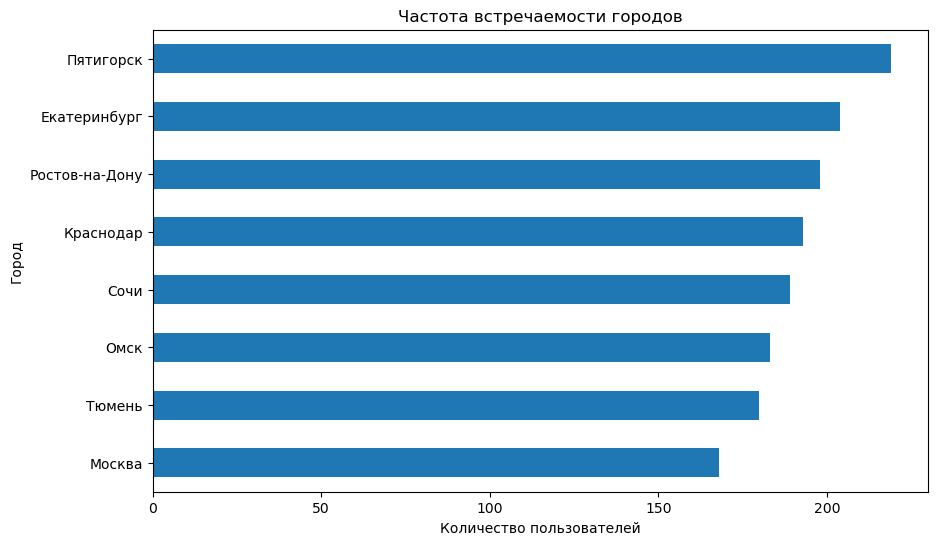

In [21]:
# Получение количества пользователей в каждом городе
city_counts = users['city'].value_counts()

# Визуализация частоты встречаемости городов
plt.figure(figsize=(10, 6))
city_counts.sort_values().plot(kind='barh')
plt.title('Частота встречаемости городов')
plt.xlabel('Количество пользователей')
plt.ylabel('Город')
plt.show()

Из графика видно, что больше всего пользователей в нашей выборке из Пятигорска, а меньше всего из Москвы.

Соотношение пользователей с подпиской и без подписки: Для определения соотношения пользователей с подпиской и без подписки, я  посчитала количество пользователей с каждым типом подписки и отобразила это на графике в виде круговой диаграммы.

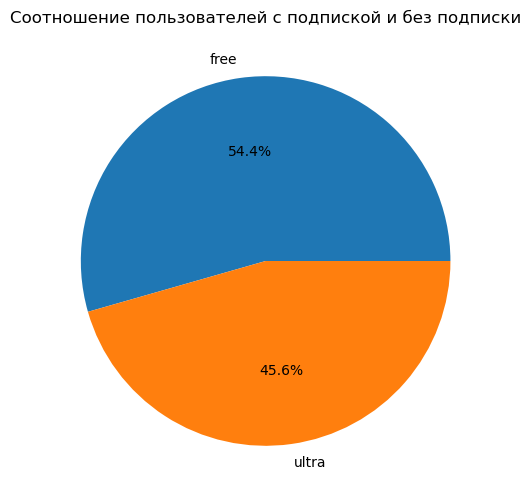

In [22]:
# Получение количества пользователей с подпиской и без подписки
subscription_counts = users['subscription_type'].value_counts()

# Визуализация соотношения пользователей с подпиской и без подписки
plt.figure(figsize=(6, 6))
subscription_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Соотношение пользователей с подпиской и без подписки')
plt.ylabel('') 
plt.show()

Из графика видно, что пользователей без подписки больше (54.4%), чем пользователей с подпиской (45.6%)

Возраст пользователей: Для определения возраста пользователей, я посчитала количество пользователей для каждого возраста и отобразила это на графике в виде гистограммы.

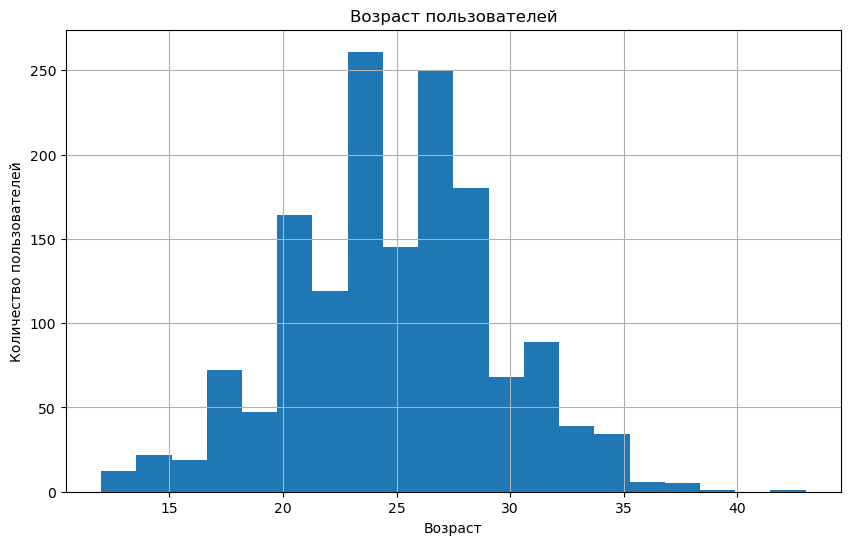

In [23]:
# Визуализация возраста пользователей
plt.figure(figsize=(10, 6))
users['age'].hist(bins=20)
plt.title('Возраст пользователей')
plt.xlabel('Возраст')
plt.ylabel('Количество пользователей')
plt.show()

Из графика видно, что есть несколько пиков по возрастам, но чаще всего встречаются пользователи в возрасте примерно 23 года и 27 лет.

In [24]:
users['age'].describe()

count    1534.000000
mean       24.903520
std         4.572367
min        12.000000
25%        22.000000
50%        25.000000
75%        28.000000
max        43.000000
Name: age, dtype: float64

С помощью метода выше можно узнать, что самому молодому пользователю приложения 12 лет, а самому взрослому - 43. Также можно упомянуть, что средний возраст пользователей приложения 24/25 лет, что также отображено на диаграмме.

Расстояние, которое пользователь преодолел за одну поездку: Для определения расстояния, которое пользователь преодолел за одну поездку, я вычислила среднее значение расстояния для каждого пользователя и отобразить это на графике в виде гистограммы.

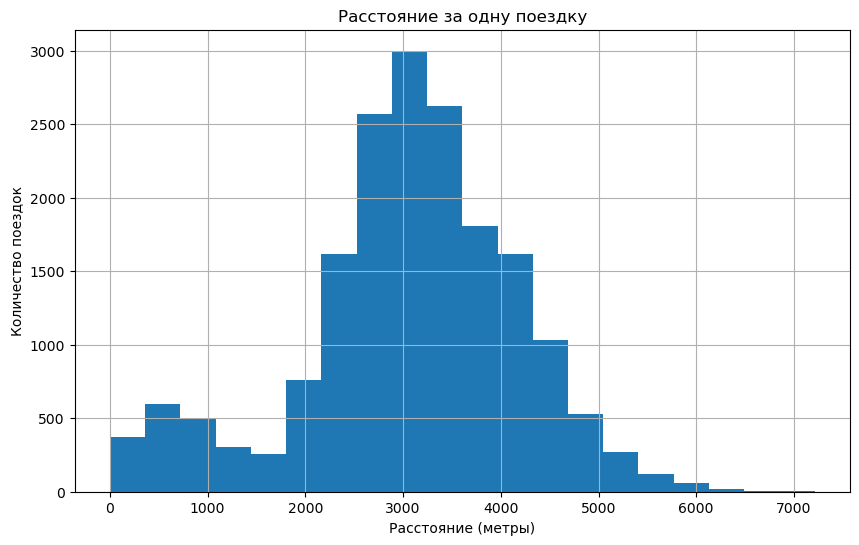

In [25]:
# Визуализация расстояния, которое пользователь преодолел за одну поездку
plt.figure(figsize=(10, 6))
rides['distance'].hist(bins=20)
plt.title('Расстояние за одну поездку')
plt.xlabel('Расстояние (метры)')
plt.ylabel('Количество поездок')
plt.show()

In [26]:
rides['distance'].describe()

count    18068.000000
mean      3070.659976
std       1116.831209
min          0.855683
25%       2543.226360
50%       3133.609994
75%       3776.222735
max       7211.007745
Name: distance, dtype: float64

Исходя из данных выше видно, что в среднем пользователи преодолевали 3070 метров за одну поездку.

Продолжительность поездок: Для определения продолжительности поездок, можно вычислить среднюю продолжительность поездки для каждого пользователя и отобразить это на графике в виде гистограммы.

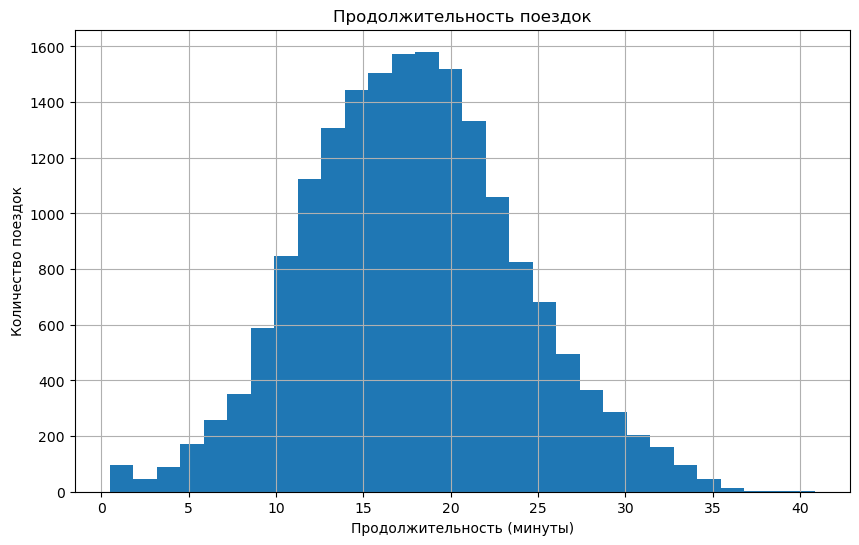

In [27]:
# Визуализация продолжительности поездок
plt.figure(figsize=(10, 6))
rides['duration'].hist(bins=30)
plt.title('Продолжительность поездок')
plt.xlabel('Продолжительность (минуты)')
plt.ylabel('Количество поездок')
plt.show()

In [28]:
rides['duration'].describe()

count    18068.000000
mean        17.805011
std          6.091051
min          0.500000
25%         13.597563
50%         17.678395
75%         21.724800
max         40.823963
Name: duration, dtype: float64

Из графика видно, что пользователи в среднем затрачивали примерно 17 минут на одну поездку. Одако на графике можно заметить еще один пик около 0, его я рассмотрела подробнее ниже.

In [29]:
duartion_min = rides.query('duration < 5')

Выделяю из всего массива данных только те поездки, длительность которых была меньше 5 минут и строю график, чтобы рассмотреть их.

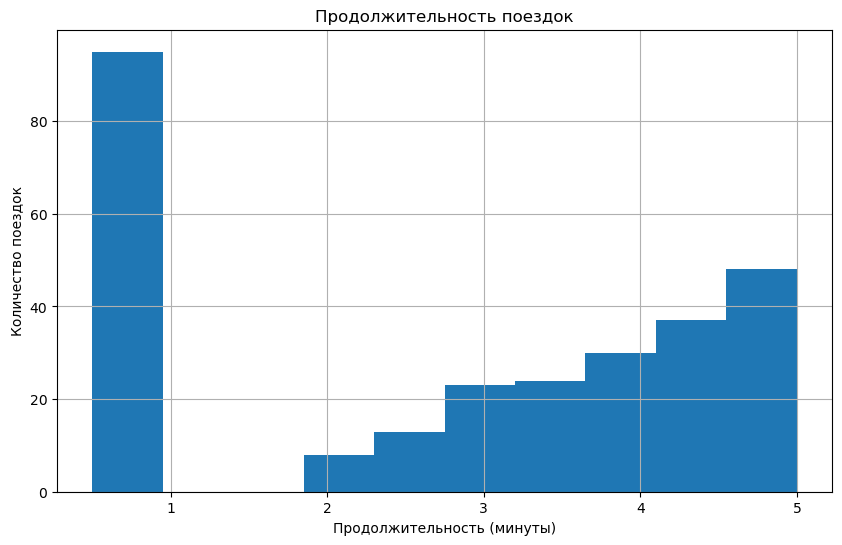

In [30]:
plt.figure(figsize=(10, 6))
duartion_min['duration'].hist(bins=10)
plt.title('Продолжительность поездок')
plt.xlabel('Продолжительность (минуты)')
plt.ylabel('Количество поездок')
plt.show()

In [31]:
duartion_min['duration'].describe()

count    278.000000
mean       2.715662
std        1.728951
min        0.500000
25%        0.500000
50%        3.192398
75%        4.316825
max        4.998773
Name: duration, dtype: float64

In [32]:
duartion_min.loc[duartion_min['duration'] < 1]

,user_id,distance,duration,date,month
6531,701,4196.445201,0.5,2021-08-31,8
6570,704,4830.824371,0.5,2021-10-14,10
6680,712,4684.004397,0.5,2021-03-04,3
6695,713,5215.642710,0.5,2021-02-25,2
6768,718,5197.436649,0.5,2021-02-11,2
...,...,...,...,...,...
17004,1460,5531.335845,0.5,2021-01-19,1
17242,1477,6724.932981,0.5,2021-01-12,1
17314,1483,4445.481070,0.5,2021-03-06,3
17505,1496,5722.551787,0.5,2021-02-14,2


Исходя из данных можно увидеть, что присутвует выброс в количестве поездок, которые длились меньше минуты, при этом расстояние, которые было преодолено составляет в целом 4-5 тысяч метров, такие данные аномальны.

Причиной таких данных может быть как техническая ошибка, так и человеческий фактор. Однако, в интересах дальнейшего анализа, я удаляю строки с короткими поездками.

In [33]:
rides = rides.loc[rides['duration'] > 1]

In [34]:
rides['duration'].describe()

count    17973.000000
mean        17.896480
std          5.975424
min          2.035632
25%         13.670439
50%         17.714122
75%         21.747016
max         40.823963
Name: duration, dtype: float64

#### Шаг 4. Объединение данных

1. Объединить данные о пользователях, поездках и подписках в один датафрейм. 
2. Создать ещё два датафрейма из только что созданного датафрейма:
    - c данными о пользователях без подписки;
    - с данными о пользователях с подпиской.
3. Визуализировать информацию о расстоянии и времени поездок для пользователей обеих категорий.

Я объединила данные о пользователях, поездках и подписках используя метод merge(). На первом этапе объединяю таблицы users и rides по столбцу user_id, при этом сохраняю все строки из таблицы users и добавляю соответствующие столбцы из таблицы rides. На следующем этапе объединяю полученный датафрейм с таблицей subs по столбцу subscription_type, при этом сохраняю все строки из объединенного датафрейма и добавляю соответствующие столбцы из таблицы subs. Результат объединения сохраняю в переменную merged_df.

In [35]:
merged_df = users.merge(rides, on='user_id', how='left').merge(subs, on='subscription_type', how='left')

In [36]:
merged_df.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,25.599769,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,15.816871,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6.232113,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,18.511000,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26.265803,2021-08-28,8,6,0,199


Самой большой по объему данных таблицей является таблица, содержащая данные о поездках. Именно к ней я присоединяю остальные данные. Поэтому дальше я смотрю, сколько строчек было в таблице с поездкам и соответсвует ли это количествую строк в объединенном датасете.

In [37]:
rides.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17973 entries, 0 to 18067
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   user_id   17973 non-null  int64         
 1   distance  17973 non-null  float64       
 2   duration  17973 non-null  float64       
 3   date      17973 non-null  datetime64[ns]
 4   month     17973 non-null  int32         
dtypes: datetime64[ns](1), float64(2), int32(1), int64(1)
memory usage: 772.3 KB


In [38]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17973 entries, 0 to 17972
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            17973 non-null  int64         
 1   name               17973 non-null  object        
 2   age                17973 non-null  int64         
 3   city               17973 non-null  object        
 4   subscription_type  17973 non-null  object        
 5   distance           17973 non-null  float64       
 6   duration           17973 non-null  float64       
 7   date               17973 non-null  datetime64[ns]
 8   month              17973 non-null  int32         
 9   minute_price       17973 non-null  int64         
 10  start_ride_price   17973 non-null  int64         
 11  subscription_fee   17973 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int32(1), int64(5), object(3)
memory usage: 1.6+ MB


Из данных выше видно, что количество строк в обеих таблицах совпадает и равно 17973.

df_without_subscription содержит данные только о пользователях без подписки. Фильтрую их, используя условие df['subscription_type'] == 'free'.

df_with_subscription содержит данные только о пользователях с подпиской "ultra". Фильтрую их, используя условие df['subscription_type'] == 'ultra'.

In [39]:
df_without_subscription = merged_df[merged_df['subscription_type'] == 'free']
df_with_subscription = merged_df[merged_df['subscription_type'] == 'ultra']

In [40]:
df_without_subscription.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
6500,700,Айдар,22,Омск,free,2515.690719,14.944286,2021-01-02,1,8,50,0
6501,700,Айдар,22,Омск,free,846.932642,16.234663,2021-02-01,2,8,50,0
6502,700,Айдар,22,Омск,free,4004.434142,20.016628,2021-02-04,2,8,50,0
6503,700,Айдар,22,Омск,free,1205.911290,9.782872,2021-02-10,2,8,50,0
6504,700,Айдар,22,Омск,free,3047.379435,17.427673,2021-02-14,2,8,50,0


In [41]:
df_with_subscription.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,25.599769,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,15.816871,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6.232113,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,18.511000,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26.265803,2021-08-28,8,6,0,199


В коде ниже я использовала гистограммы, чтобы визуализировать расстояние и продолжительность поездок для пользователей обеих категорий.

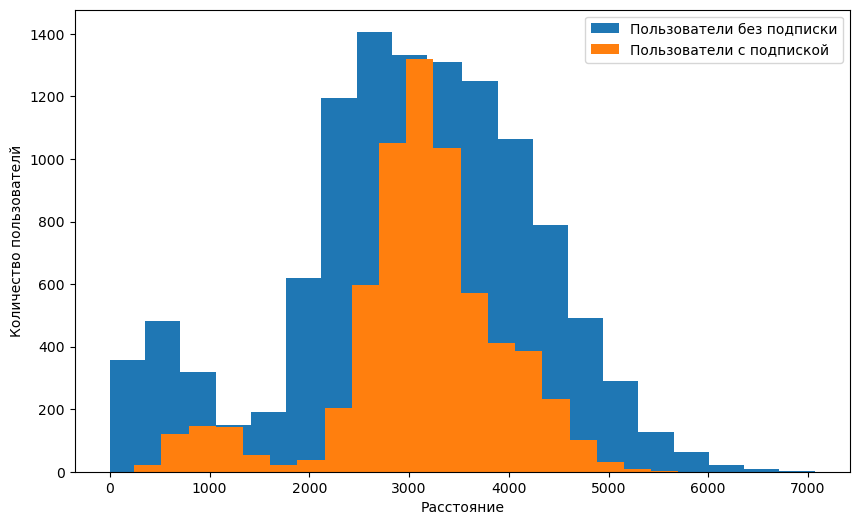

In [42]:
plt.figure(figsize=(10, 6))
plt.hist(df_without_subscription['distance'], label='Пользователи без подписки', bins=20)
plt.hist(df_with_subscription['distance'], label='Пользователи с подпиской', bins = 20)
plt.xlabel('Расстояние')
plt.ylabel('Количество пользователй')
plt.legend()
plt.show()

Как можно заметить расстояние, которое преодолели пользователи с подпиской в среднем больше, чем то, которое преодолели пользователи без подписки.

Также можно увидеть, что у обоих типов пользователей присутвует два пика: один на расстоянии примерно 3000 метров, а другой пик находится на 1000 метров для пользователей с подпиской и примерно на 500 метрах для пользователей без подписки.

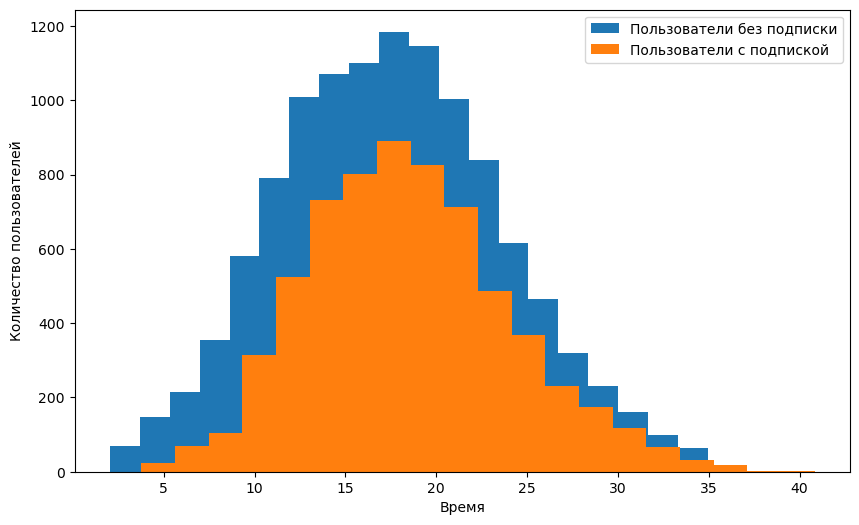

In [43]:
plt.figure(figsize=(10, 6))
plt.hist(df_without_subscription['duration'], label='Пользователи без подписки', bins=20)
plt.hist(df_with_subscription['duration'], label='Пользователи с подпиской', bins=20)
plt.xlabel('Время')
plt.ylabel('Количество пользователей')
plt.legend()
plt.show()

Касательно времени поездки то здесь можно заметить, что значения для обеих категорий пользователей нормально распределены со средним значением равным примерно 17 минутам.

#### Шаг 5. Подсчёт выручки

1. Создать датафрейм с агрегированными данными о поездках на основе датафрейма с объединёнными данными из шага 4: найти суммарное расстояние, количество поездок и суммарное время для каждого пользователя за каждый месяц.
2. В этот же датафрейм добавить столбец с помесячной выручкой, которую принёс каждый пользователь. 

Для создания датафрейма с агрегированными данными о поездках на основе объединенных данных я сгруппировала данные по пользователю и месяцу, а затем произвела агрегацию. Для этого использовала метод groupby() и функции агрегации, такие как sum() и count(). В этом коде я использую метод groupby для группировки данных по столбцам "user_id" и "month". Затем использую метод agg для агрегирования данных, где для столбца "distance" вычисляю сумму, для столбца "duration" также вычисляю сумму, а для столбца "user_id" вычисляю количество поездок. Я также переименовываю столбец "user_id" в "trips", чтобы отразить, что это количество поездок. Затем сбрасываю индекс, чтобы получить датафрейм с агрегированными данными.

Результатом данного кода является новый датафрейм monthly_df, в котором для каждого пользователя и каждого месяца указаны суммарное расстояние, количество поездок и суммарное время.

In [44]:
merged_df['duration'] = np.ceil(merged_df['duration'])

Первым делом я округляю данные о длительности поездок для упрощения расчетов.

In [45]:
monthly_df = (merged_df.groupby(['user_id', 'month'])
                        .agg({'distance': 'sum', 'duration': 'sum', 'user_id': 'count', 'start_ride_price': 'first', 'minute_price':'first', 'subscription_fee':'first'})
                        .rename(columns={'user_id': 'trips'}).reset_index())

In [46]:
monthly_df.head()

,user_id,month,distance,duration,trips,start_ride_price,minute_price,subscription_fee
0,1,1,7027.511294,42.0,2,0,6,199
1,1,4,754.159807,7.0,1,0,6,199
2,1,8,6723.470560,46.0,2,0,6,199
3,1,10,5809.911100,32.0,2,0,6,199
4,1,11,7003.499363,56.0,3,0,6,199


Для добавления столбца с помесячной выручкой использованы значения столбцов 'start_ride_price', 'minute_price', 'duration' (продолжительность округлена с помощью np.ceil()) и 'subscription_fee'. Формула для вычисления выручки: (стоимость старта поездки × количество поездок) + (стоимость одной минуты поездки × общая продолжительность всех поездок в минутах) + стоимость подписки.

In [47]:
monthly_df['revenue'] = (monthly_df['start_ride_price'] * monthly_df['trips']) + (monthly_df['minute_price'] * monthly_df['duration']) + monthly_df['subscription_fee']

In [48]:
monthly_df.head()

,user_id,month,distance,duration,trips,start_ride_price,minute_price,subscription_fee,revenue
0,1,1,7027.511294,42.0,2,0,6,199,451.0
1,1,4,754.159807,7.0,1,0,6,199,241.0
2,1,8,6723.470560,46.0,2,0,6,199,475.0
3,1,10,5809.911100,32.0,2,0,6,199,391.0
4,1,11,7003.499363,56.0,3,0,6,199,535.0


Для упрощения дальнейшей работы с таблицей добавлю колонку с типом подписки.

In [49]:
monthly_df.loc[monthly_df['subscription_fee'] == 0, 'subscription_type'] = 'free'
monthly_df.loc[monthly_df['subscription_fee'] == 199, 'subscription_type'] = 'ultra'

In [50]:
monthly_df.head()

,user_id,month,distance,duration,trips,start_ride_price,minute_price,subscription_fee,revenue,subscription_type
0,1,1,7027.511294,42.0,2,0,6,199,451.0,ultra
1,1,4,754.159807,7.0,1,0,6,199,241.0,ultra
2,1,8,6723.470560,46.0,2,0,6,199,475.0,ultra
3,1,10,5809.911100,32.0,2,0,6,199,391.0,ultra
4,1,11,7003.499363,56.0,3,0,6,199,535.0,ultra


Теперь у нас есть таблица, в которой видно какие поездки совершал каждый пользователь, в какой месяц и какую вырочку это принесло компании.

#### Шаг 6. Проверка гипотез

Продакт-менеджеры сервиса хотят увеличить количество пользователей с подпиской. Для этого они будут проводить различные акции, но сначала нужно выяснить несколько важных моментов.
1. Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Если да, то пользователи с подпиской могут быть «выгоднее» для компании. Проверить гипотезу. 
2. Расстояние одной поездки в 3130 метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, не превышает 3130 метров? 
3. Проверить гипотезу о том, будет ли помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки. 
4. Гипотетическая ситуация: техническая команда сервиса обновила сервера, с которыми взаимодействует мобильное приложение. Она надеется, что из-за этого количество обращений в техподдержку значимо снизилось. Некоторый файл содержит для каждого пользователя данные о количестве обращений до обновления и после него. Какой тест нам понадобился бы для проверки этой гипотезы?

1. Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Если да, то пользователи с подпиской могут быть «выгоднее» для компании. 

Формулирую гипотезы: 

Нулевая гипотеза: Средняя продолжительность поездок у клиентов с подпиской и без нее равна

Альтернативная гипотеза: Средняя продолжительность поездок у клиентов с подпиской больше чем у клиентов без нее

Для проверки этих гипотез буду использовать специальный метод для проверки гипотезы о равенстве среднего двух генеральных совокупностей по взятым из них выборкам: `scipy.stats.ttest_ind(array1, array2, equal_var, alternative)`.

In [51]:
#Первым шагом необходимо выделить столбцы duration для пользователей с подпиской и без подписки
duration_without_subscription = df_without_subscription['duration']
duration_with_subscription = df_with_subscription['duration']

In [52]:
#Затем проводим t-тест
t_statistic, p_value = stats.ttest_ind( duration_with_subscription, duration_without_subscription, alternative='greater')

In [53]:
#Оценим значимость различий в средних значениях duration
alpha = 0.05
if p_value < alpha:
    print("Средняя продолжительность поездок у клиентов с подпиской больше чем у клиентов без нее")
else:
    print("Средняя продолжительность поездок у клиентов с подпиской и без подписки одинакова.")
    
print('p_value:', p_value)

#Считаем и выводим на экран какая средняя продолжительность поездки была у каждого типа пользователя
print('Средняя продолжительность поездок у клиентов с подпиской:', round(df_with_subscription['duration'].mean(), 2))
print('Средняя продолжительность поездок у клиентов без подпискои:', round(df_without_subscription['duration'].mean(), 2))

Средняя продолжительность поездок у клиентов с подпиской больше чем у клиентов без нее
p_value: 4.704468074453899e-28
Средняя продолжительность поездок у клиентов с подпиской: 18.54
Средняя продолжительность поездок у клиентов без подпискои: 17.53


Данные результаты позволяют нам отвергнуть нулевую гипотезу и предположить, что пользователи с подпиской тратят больше времени на поездки, чем пользователи без неё.

2. Расстояние одной поездки в 3130 метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, не превышает 3130 метров?

Гипотезы:

Нулевая гипотеза: среднее расстояние которое проезжает пользователь с подпиской за одну поездку равно 3130 метрам или меньше

Альтернативная гипотеза: среднее расстояние за одну поездку больше 3130 метров

Для проверки этой гипотезы буду использовать метод `scipy.stats.ttest_1samp(a, popmean, alternative)`

In [54]:
#Выделаеям столбец с расстоянием для пользователей с подпиской и устанавливаем оптимальное значение
distance_with_subscription = df_with_subscription['distance']
distance_optimal = 3130

In [55]:
#Проводим t-тест
alpha = 0.05
results = stats.ttest_1samp(
    distance_with_subscription,
    distance_optimal,
    alternative='greater')

In [56]:
#Проверяем гипотезы
if (results.pvalue < alpha):
    print('Среднее расстояние за одну поездку больше 3130 метров')
else:
    print('Среднее расстояние которое проезжает пользователь с подпиской за одну поездку меньше или равно 3130 метрам')
    
print('p_value:', results.pvalue)

Среднее расстояние которое проезжает пользователь с подпиской за одну поездку меньше или равно 3130 метрам
p_value: 0.9195368847849785


Данные результаты не позволяют мне отвергнуть нулевую гипотезу. Это значит, что пользователи с подпиской за одну поездку в среднем преодолевают расстовние меньше 3130 метров.

3. Проверить гипотезу о том, будет ли помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки. 

Нулевая гипотеза: помесячная выручка от пользователей с подпиской равна помесячной выручке от пользователей без подписки

Альтернативная гипотеза: помесячная выручка пользователей с подпиской больше чем выручка пользователей без подписки 

В Python есть специальный метод для проверки гипотезы о равенстве среднего двух генеральных совокупностей по взятым из них выборкам: scipy.stats.ttest_ind(array1, array2, equal_var, alternative). Аргумент 'greater' может использоваться для проверки альтернативной гипотезы «Среднее значение первой генеральной совокупности больше среднего значения второй генеральной совокупности»

In [57]:
# Разделение данных на две группы по наличию подписки
data_with_sub = monthly_df[monthly_df['subscription_type'] == 'ultra']['revenue']
data_without_sub = monthly_df[monthly_df['subscription_type'] == 'free']['revenue']

In [58]:
# Проведение t-теста
t_stat, p_value = stats.ttest_ind(data_with_sub, data_without_sub, alternative='greater')

# Оценка результатов теста
alpha = 0.05

if p_value < alpha:
    print("Помесячная выручка пользователей с подпиской больше чем выручка пользователей без подписки")
else:
    print("Нет статистически значимых различий в выручке")
    
print('p_value:', p_value)

Помесячная выручка пользователей с подпиской больше чем выручка пользователей без подписки
p_value: 2.0314113674863288e-30


Исходя из результатов теста можно отвергнуть нулевую гипотезу и утверждать, что пользователи с подпиской приносят больше выручки, чем пользователи без нее.

4. Ситуация: техническая команда сервиса обновила сервера, с которыми взаимодействует мобильное приложение. Она надеется, что из-за этого количество обращений в техподдержку значимо снизилось. Некоторый файл содержит для каждого пользователя данные о количестве обращений до обновления и после него. Какой тест понадобился бы для проверки этой гипотезы?

Для проверки гипотезы о снижении количества обращений в техподдержку после обновления серверов можно использовать тест на сравнение средних для зависимых (парных) выборок (scipy.stats.ttest_rel()). В качестве связанных выборок можно использовать данные о количестве обращений каждого пользователя до и после обновления серверов. Посчитать среднее количество обращений до и после обновления. Провести scipy.stats.ttest_rel() для проверки гипотезы о различии средних значений до и после обновления. Интерпретировать результаты. Если среднее количество обращений после обновления статистически значимо ниже, можно сделать вывод о значимом снижении количества обращений в техподдержку после обновления серверов.

<h1>Выводы</h1>

Для данного исследования мне было предоставлено три таблицы хранящие разные наборы данных касательно пользователей сервиса GoFast: информация о пользователях, информация о поездках, категории подписок. В рамках данной работы я объединила и проанализировала представленные данные. 

Главной целью этого исследования стояло выяснить являются ли пользователи с подпиской более выгодными для компании, чем пользователи без нее. 

Прежде чем перейти к финальным выводам, я бы хотела для начала поделится основной информации о той базе данных, с которой я работала.

В результате проведенного исследования было обнаружено, что в базе данных присутствуют информация о 1565 пользователях, которые совершили 18068 поездок. Большинство пользователей проживает в городе Пятигорске, а меньше всего в Москве. Большинство пользователей не имеют подписки (54.4%), в то время как 45.6% пользователей являются подписчиками. Возрастные группы пользователей имеют несколько пиков, самые распространенные возраста - около 23 и 27 лет. Самому молодому пользователю приложения 12 лет, а самому взрослому - 43. Средний возраст пользователей составляет примерно 24/25 лет. Среднее пройденное расстояние за одну поездку составляет 3070 метров, а средняя длительность поездки - около 17 минут. Наблюдения о выбросе данных, где поездка длится менее минуты, указывают на возможное наличие технических ошибок или человеческого фактора. В целях точности исследования, записи с короткими поездками были удалены.

Для дальнейшей работы было решено объединить данные в одну таблицу.
Анализ данных показал, что таблица с информацией о поездках является самой большой по объему. Поэтому было решено присоединить к ней данные о пользователях и подписках. Количество строк в объединенном датасете совпадает с количеством строк в исходных таблицах (17973 строк).

Расстояние, преодоленное пользователями с подпиской, оказалось в среднем больше, чем у пользователей без подписки. Оба типа пользователей имеют два пика расстояния - около 3000 метров и около 1000 метров для пользователей с подпиской, около 500 метров для пользователей без подписки.

Относительно времени поездки, значения для обоих типов пользователей распределены нормально с примерно одинаковым средним временем в 17 минут.

В дальнейшем был создан датафрейм с агрегированными данными о поездках, в котором указаны поездки каждого пользователя, месяц и прибыль компании от этих поездок.

После чего я перешла к проверке гипотез и вот какие выводы были сделаны:

1. Пользователи с подпиской тратят больше времени на поездки по сравнению с пользователями без подписки. Это может быть выгодным для компании.
2. Среднее расстояние, которое проезжают пользователи с подпиской за одну поездку, не превышает 3130 метров (оптимальное расстояние с точки зрения износа самоката).
3. Помесячная выручка от пользователей с подпиской выше, чем выручка от пользователей без подписки.

Таким образом, <b>общий вывод</b> исследования состоит в том, что пользователи с подпиской проводят больше времени в поездках, приносят большую выручку и не превышают оптимальное расстояние поездки, что делает их более выгодными для компании, чем пользователи без подписки. 

На основе данных и выводов, предлагаю следующие рекомендации для будущих исследований:

1. Расширить объем исследования, включив больше временных и географических данных, чтобы увидеть, есть ли различия в поведении пользователей с подпиской и без подписки в разных регионах или в разное время года. Это поможет лучше понять факторы, влияющие на использование подписки и оптимальные условия для использования сервиса.
2. Изучить более подробно поведение пользователей с подпиской в разных возрастных группах. Возможно, есть определенная группа пользователей, которые активнее и более склонны к пользованию подпиской. Это поможет компании более точно нацелить свои маркетинговые и рекламные усилия.
3. Исследовать мотивацию пользователей с подпиской. Почему они выбирают подписку, что их привлекает в ее использовании? Это может помочь улучшить условия подписки и привлечь больше пользователей к ее использованию.
4. Изучить влияние маркетинговых акций и скидок на использование подписки. Какие акции и скидки на подписку привлекают больше пользователей? Как они влияют на их поведение и выручку компании?

Эти рекомендации помогут компании лучше понять и оптимизировать использование подписки, привлечь больше пользователей и увеличить выручку.
